# Lab 6: Decision Tree Classification

**Objective:** Train and visualize a Decision Tree classifier using the Wine Quality dataset. Study how changing the **maximum tree depth** and the **splitting criterion** (`gini` and `entropy`) affects classification performance.

**Dataset:** `winequality.zip` (contains `winequality-red.csv`). The target column is `quality`.

> **Before running:** Keep this notebook and `winequality.zip` in the same folder. Then run the cells from top to bottom.

## 1. Import the required libraries

We use pandas to work with the dataset, Matplotlib to create graphs, and scikit-learn to train and evaluate the Decision Tree.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from io import BytesIO

import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the dataset

The code first looks for `winequality.zip`. If the CSV has already been extracted, it can also read `winequality-red.csv` directly.

In [2]:
zip_path = Path("winequality.zip")
csv_path = Path("winequality-red.csv")

if zip_path.exists():
    with ZipFile(zip_path, "r") as zip_file:
        csv_files = [name for name in zip_file.namelist() if name.lower().endswith(".csv")]
        if not csv_files:
            raise FileNotFoundError("No CSV file was found inside winequality.zip.")
        csv_bytes = zip_file.read(csv_files[0])
        data = pd.read_csv(BytesIO(csv_bytes), sep=None, engine="python")
elif csv_path.exists():
    data = pd.read_csv(csv_path, sep=None, engine="python")
else:
    raise FileNotFoundError(
        "Dataset not found. Put winequality.zip or winequality-red.csv in the same folder as this notebook."
    )

print("Dataset loaded successfully.")
print("Dataset shape:", data.shape)
data.head()

Dataset loaded successfully.
Dataset shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 3. Understand and prepare the data

Each row represents a red wine sample. The input columns contain chemical measurements. The `quality` column is the class we want the model to predict.

We check the data types, missing values, and the number of samples in each quality class.

In [3]:
print("Column names:")
print(data.columns.tolist())

print("\nData types and non-null counts:")
data.info()

print("\nMissing values:")
print(data.isnull().sum())

print("\nNumber of samples in each quality class:")
print(data["quality"].value_counts().sort_index())

Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  qualit

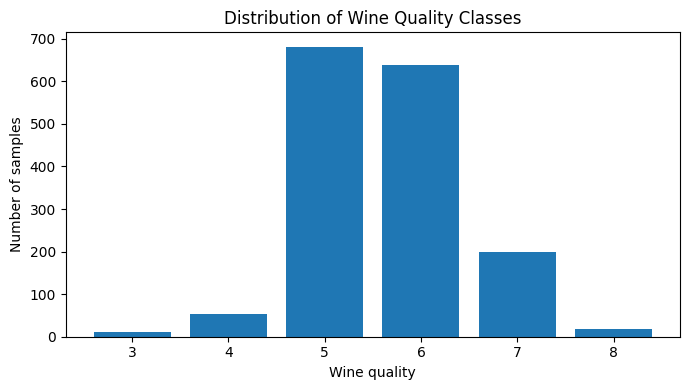

In [4]:
# Visualize the number of samples in each quality class.
class_counts = data["quality"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar(class_counts.index.astype(str), class_counts.values)
plt.title("Distribution of Wine Quality Classes")
plt.xlabel("Wine quality")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.show()

### Separate features and target

- **Features (X):** all columns except `quality`.
- **Target (y):** the `quality` column.

We use an 80:20 train-test split. `stratify=y` keeps approximately the same class distribution in both sets. Decision Trees do not require feature scaling, so we can use the original feature values.

In [5]:
X = data.drop(columns=["quality"])
y = data["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of input features:", X_train.shape[1])

Training samples: 1279
Testing samples: 320
Number of input features: 11


## 4. Train Decision Tree models with different depths and criteria

A Decision Tree repeatedly splits the data into smaller groups.

- **`max_depth`:** limits how many levels the tree can have. A small depth may underfit; a very deep tree may overfit.
- **`criterion='gini'`:** uses Gini impurity to choose a split.
- **`criterion='entropy'`:** uses information gain (based on entropy) to choose a split.

We test several depths with both splitting criteria and compare training and testing accuracy, precision, recall, and F1-score. Weighted averages are used because the quality classes do not have equal numbers of samples.

In [6]:
depth_values = [1, 2, 3, 4, 5, 6, 8, 10, None]
criteria = ["gini", "entropy"]

results = []
trained_models = {}

for criterion in criteria:
    for depth in depth_values:
        model = DecisionTreeClassifier(
            criterion=criterion,
            max_depth=depth,
            random_state=RANDOM_STATE,
        )
        model.fit(X_train, y_train)

        train_predictions = model.predict(X_train)
        test_predictions = model.predict(X_test)

        results.append({
            "criterion": criterion,
            "max_depth": depth,
            "train_accuracy": accuracy_score(y_train, train_predictions),
            "test_accuracy": accuracy_score(y_test, test_predictions),
            "precision_weighted": precision_score(y_test, test_predictions, average="weighted", zero_division=0),
            "recall_weighted": recall_score(y_test, test_predictions, average="weighted", zero_division=0),
            "f1_weighted": f1_score(y_test, test_predictions, average="weighted", zero_division=0),
            "actual_depth": model.get_depth(),
            "number_of_leaves": model.get_n_leaves(),
        })
        trained_models[(criterion, depth)] = model

results_df = pd.DataFrame(results)
print("Model comparison (higher test scores are better):")
display(results_df.round(3))

Model comparison (higher test scores are better):


,criterion,max_depth,train_accuracy,test_accuracy,precision_weighted,recall_weighted,f1_weighted,actual_depth,number_of_leaves
0,gini,1.0,0.568,0.531,0.439,0.531,0.481,1,2
1,gini,2.0,0.570,0.512,0.482,0.512,0.494,2,4
2,gini,3.0,0.578,0.522,0.491,0.522,0.503,3,8
3,gini,4.0,0.630,0.562,0.538,0.562,0.545,4,16
4,gini,5.0,0.660,0.584,0.556,0.584,0.568,5,30
5,gini,6.0,0.712,0.575,0.560,0.575,0.564,6,54
6,gini,8.0,0.802,0.581,0.585,0.581,0.575,8,123
7,gini,10.0,0.894,0.591,0.594,0.591,0.591,10,203
8,gini,NaN,1.000,0.606,0.610,0.606,0.607,21,338
9,entropy,1.0,0.561,0.522,0.422,0.522,0.460,1,2


## 5. Study the effect of tree depth

The following graph compares test accuracy for `gini` and `entropy` as the maximum depth changes. The unlimited-depth model (`max_depth=None`) is included in the results table but left off the x-axis because it does not have a numeric depth limit.

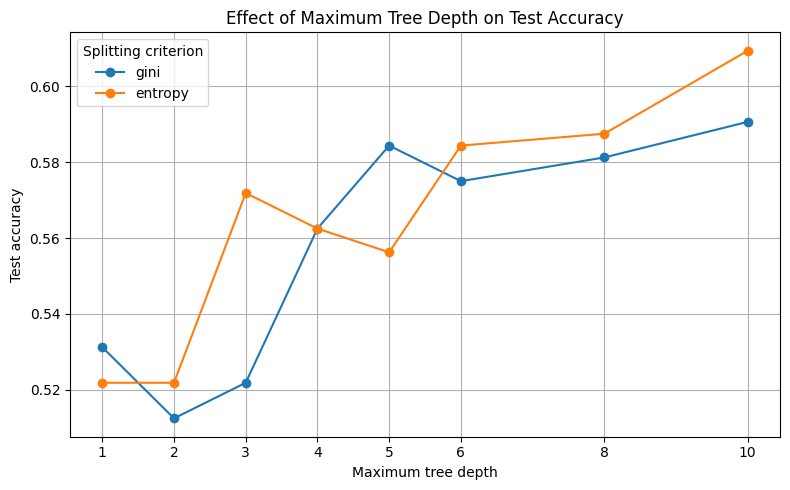

In [7]:
plt.figure(figsize=(8, 5))

for criterion in criteria:
    subset = results_df[
        (results_df["criterion"] == criterion) & (results_df["max_depth"].notna())
    ].sort_values("max_depth")
    plt.plot(
        subset["max_depth"],
        subset["test_accuracy"],
        marker="o",
        label=criterion,
    )

plt.title("Effect of Maximum Tree Depth on Test Accuracy")
plt.xlabel("Maximum tree depth")
plt.ylabel("Test accuracy")
plt.xticks([1, 2, 3, 4, 5, 6, 8, 10])
plt.grid(True)
plt.legend(title="Splitting criterion")
plt.tight_layout()
plt.show()

## 6. Compare the splitting criteria

For each criterion, show the depth that achieved the highest weighted F1-score on this test split. This is a comparison on one split, so small differences should not be treated as proof that one criterion is always better.

In [8]:
summary_rows = []
for criterion in criteria:
    criterion_results = results_df[results_df["criterion"] == criterion]
    best_row = criterion_results.loc[criterion_results["f1_weighted"].idxmax()]
    summary_rows.append({
        "criterion": criterion,
        "best_max_depth": best_row["max_depth"],
        "test_accuracy": best_row["test_accuracy"],
        "weighted_precision": best_row["precision_weighted"],
        "weighted_recall": best_row["recall_weighted"],
        "weighted_f1": best_row["f1_weighted"],
    })

criteria_summary = pd.DataFrame(summary_rows)
display(criteria_summary.round(3))

best_accuracy_row = results_df.loc[results_df["test_accuracy"].idxmax()]
print(
    "Highest test accuracy in this experiment:",
    f"criterion={best_accuracy_row['criterion']},",
    f"max_depth={best_accuracy_row['max_depth']},",
    f"accuracy={best_accuracy_row['test_accuracy']:.3f}"
)

unlimited_rows = results_df[results_df["max_depth"].isna()]
print("\nUnlimited-depth models:")
display(unlimited_rows[["criterion", "train_accuracy", "test_accuracy", "f1_weighted", "actual_depth", "number_of_leaves"]].round(3))

,criterion,best_max_depth,test_accuracy,weighted_precision,weighted_recall,weighted_f1
0,gini,NaN,0.606,0.610,0.606,0.607
1,entropy,10.0,0.609,0.606,0.609,0.607


Highest test accuracy in this experiment: criterion=entropy, max_depth=10.0, accuracy=0.609

Unlimited-depth models:


,criterion,train_accuracy,test_accuracy,f1_weighted,actual_depth,number_of_leaves
8,gini,1.0,0.606,0.607,21,338
17,entropy,1.0,0.594,0.591,19,297
